In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans,DBSCAN

In [39]:
df = pd.read_csv('/content/Mall_Customers.csv')
df

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [40]:
df.head()
df.shape

(200, 5)

In [41]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [42]:
df.isnull().sum()

,0
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


In [43]:
df.duplicated().sum()

np.int64(0)

In [44]:
df.columns

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')

In [45]:
out_col=['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)']

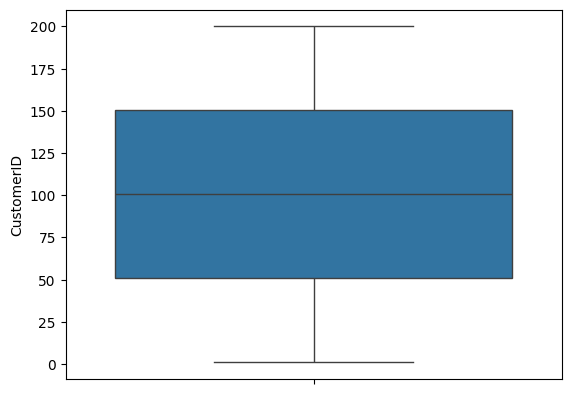

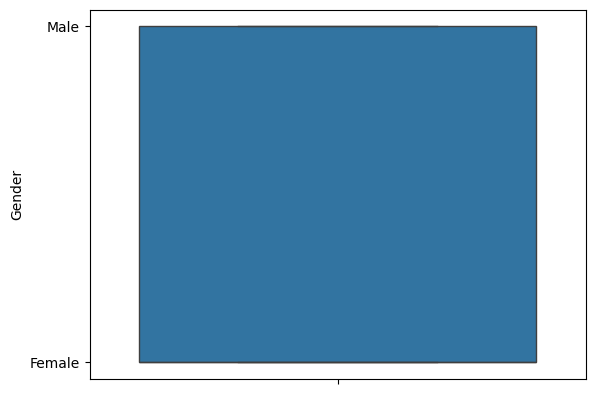

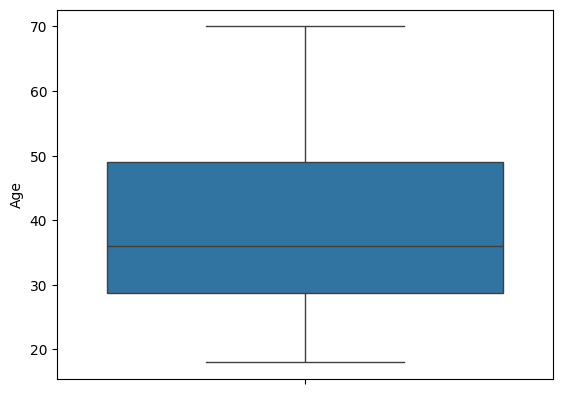

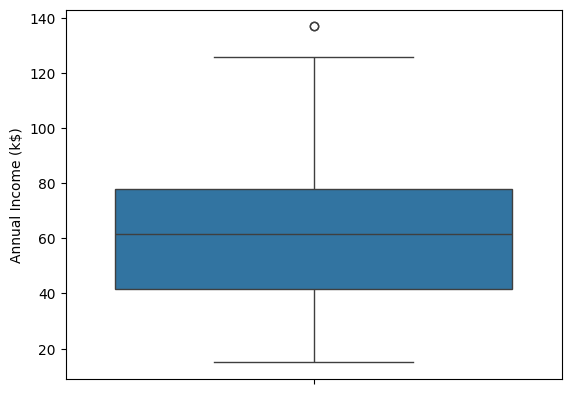

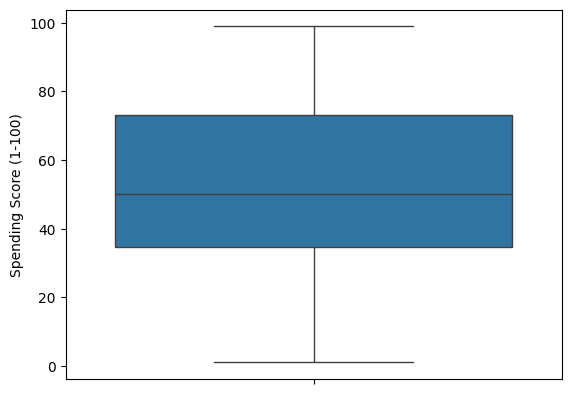

In [46]:
for col in out_col:
  sns.boxplot(df[col])
  plt.show()

In [47]:
X= df[['Age', 'Annual Income (k$)','Spending Score (1-100)']]

In [48]:
X.head()

,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


In [49]:
scaler=StandardScaler()
X=scaler.fit_transform(X)

In [51]:
inertia = []

for k in range(1, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X)

    inertia.append(kmeans.inertia_)

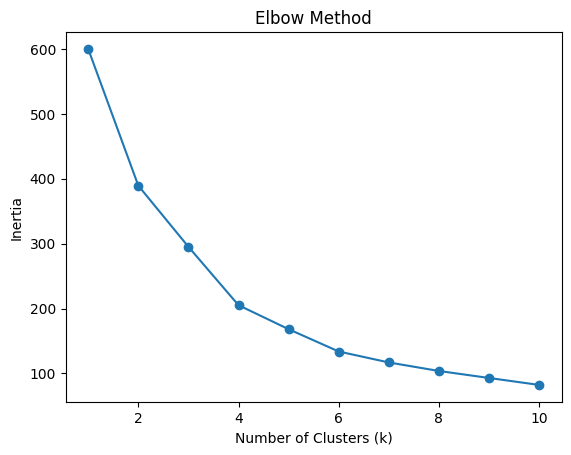

In [52]:
plt.plot(range(1, 11), inertia, marker='o')

plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method')

plt.show()

In [53]:
k=4

In [56]:
k_means=KMeans(n_clusters=4,random_state=42)
k_prediction=k_means.fit_predict(X)

df['KMeans_cluster']= k_prediction

In [57]:
df['KMeans_cluster'].value_counts()

,count
KMeans_cluster,
0,65
2,57
1,40
3,38


In [73]:
dbscan=DBSCAN(eps = 0.3,min_samples=7)
dbscan_prediction=dbscan.fit_predict(X)

df['dbscan_cluster']= dbscan_prediction

In [71]:
df['dbscan_cluster'].value_counts()

,count
dbscan_cluster,
-1,103
10,20
2,19
6,11
5,10
8,8
7,7
0,6
3,4


In [61]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

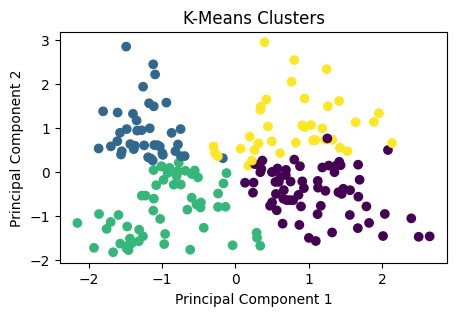

In [63]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 3))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=k_prediction,
    cmap='viridis'
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('K-Means Clusters')

plt.show()

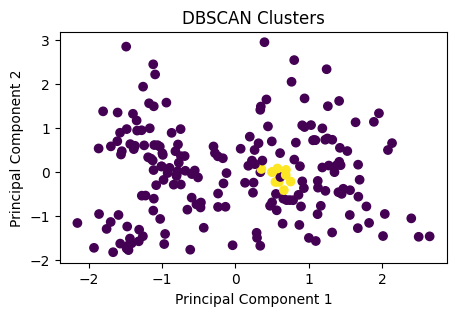

In [74]:
plt.figure(figsize=(5, 3))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=dbscan_prediction,
    cmap='viridis'
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('DBSCAN Clusters')

plt.show()